# 使用真实数据，测试 factors/diagnostic_portfolio 模块

In [1]:
from factors.library.momentum import MomentumFactor
from factors.diagnostic_portfolio import DiagnosticPortfolioExperimentRunner
from factors.dataset import ResearchDatasetBuilder
from factors.models import DatasetSpec, UniverseSpec, DataRequirement
from data.config import RolloverConfig, AdjustmentConfig, SamplingConfig, EnvironmentConfig
from data import DataFacade
from factors.preprocess import (
    PreprocessingPipeline, CrossSectionalMissingHandler, RollingTimeSeriesMissingHandler,
    CrossSectionalWinsorizer, RollingTimeseriesWinsorizer, 
)
from factors.diagnostic_portfolio import (
    DiagnosticPortfolioExperimentRunner, 
    DiagnosticPortfolioSpec,
    DiagnosticSignal,
    RebalanceConfig, 
    RiskConfig,
    CostConfig,
    ConstraintConfig
)
from factors.profiles import market_rank_ls, ts_inv_vol_gross_one, ts_inv_vol_target_vol                                   

In [2]:
roll_config = RolloverConfig()
adj_config = AdjustmentConfig()
sample_config = SamplingConfig()
env_config = EnvironmentConfig()
facade_config = (roll_config, adj_config, sample_config, env_config)

facade = DataFacade(*facade_config)

products = facade.rule_query.get_product_universe(return_type='list')
products = [x for x in products if x not in ('L_F', 'PP_F', 'V_F')]

req1 = DataRequirement(source='main_panel', )
data_req = (req1, )

uni_spec = UniverseSpec(min_average_volume=10000)

data_spec = DatasetSpec(facade_config=facade_config,products=tuple(products),
                        data_requirements=data_req, universe=uni_spec)

builder = ResearchDatasetBuilder(spec=data_spec)
dataset = builder.build()


【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\A_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AD_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AG_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AL_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AO_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AP_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\AU_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\B_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\BB_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持久化的 master_table: db\derived\master_tables\BC_b3_r110_t1.parquet
【ContinuousContractManager】加载本地持

In [3]:
print(f'main_panel: \n {dataset.main_panel.head().to_string()}')
print(f'quality: \n {dataset.quality}')
print(f'universe: \n {dataset.universe}')
print(f'auxiliary: \n {dataset.auxiliary}')

main_panel: 
                    Dominant_Contract  Price_Gap  Adj_Factor roll_state  is_roll  is_contract_switch  continuity_segment_id exchange  pre_close  pre_settle  Raw_Open  Raw_High  Raw_Low  Raw_Close   Settle  change1  change2  Volume  amount  OpenInterest  oi_chg  upper_limit  lower_limit trading_date  Adj_Open  Adj_High  Adj_Low  Adj_Close  True_Return
timestamp  product                                                                                                                                                                                                                                                                                                                                             
1995-04-17 AL                   None        NaN      6725.0    unknown     <NA>                <NA>                   <NA>      NaN        NaN         NaN       NaN       NaN      NaN        NaN      NaN      NaN      NaN     NaN     NaN           NaN     NaN          NaN          

In [4]:
import json

quality = dataset.quality

print("=" * 60)
print("数据质量摘要 (DataQualitySummary)")
print("=" * 60)

print(f"\n是否通过校验 (is_valid): {quality.is_valid}")

print(f"\n总行数 (total_rows): {quality.total_rows:,}")

print(f"\n各品种样本数 (product_sample_counts): 共 {len(quality.product_sample_counts)} 个品种")
# 按行数降序展示
for product, count in sorted(quality.product_sample_counts.items(), key=lambda x: -x[1]):
    print(f"  {product:<6} {count:>8,}")

print(f"\n各列缺失率 (missing_rate_by_column):")
for col, rate in quality.missing_rate_by_column.items():
    print(f"  {col:<20} {rate:.4%}")

print(f"\n警告 (warnings): {len(quality.warnings)} 条")
for w in quality.warnings:
    print(f"  - {w}")

print(f"\n错误 (errors): {len(quality.errors)} 条")
for e in quality.errors:
    print(f"  - {e}")

print("=" * 60)

数据质量摘要 (DataQualitySummary)

是否通过校验 (is_valid): True

总行数 (total_rows): 252,593

各品种样本数 (product_sample_counts): 共 94 个品种
  AL        7,592
  CU        7,592
  RU        7,572
  A         6,661
  M         6,298
  CF        5,366
  FU        5,305
  C         5,285
  B         5,225
  SR        4,973
  Y         4,972
  TA        4,742
  ZN        4,680
  L         4,594
  P         4,535
  AU        4,485
  RB        4,190
  WR        4,190
  V         4,151
  IF        3,932
  PB        3,706
  J         3,692
  PM        3,505
  AG        3,433
  OI        3,387
  RI        3,381
  WH        3,381
  WT        3,367
  FG        3,292
  RM        3,273
  RS        3,273
  JM        3,221
  TF        3,109
  BU        3,093
  I         3,086
  JD        3,071
  JR        3,065
  BB        3,051
  FB        3,051
  PP        2,997
  HC        2,982
  MA        2,924
  SF        2,886
  SM        2,886
  LR        2,805
  CS        2,797
  T         2,739
  NI        2,734
  SN        2,

In [5]:
momentum = MomentumFactor(lookback=20)
mom20 = momentum.compute(data=dataset.main_panel)
print(mom20)


timestamp   product
1995-04-17  AL              NaN
            CU              NaN
1995-04-18  AL              NaN
            CU              NaN
1995-04-19  AL              NaN
                         ...   
2026-06-26  WH              NaN
            WR        -0.003228
            Y         -0.011361
            ZC              NaN
            ZN        -0.030565
Name: momentum_20, Length: 252593, dtype: float64


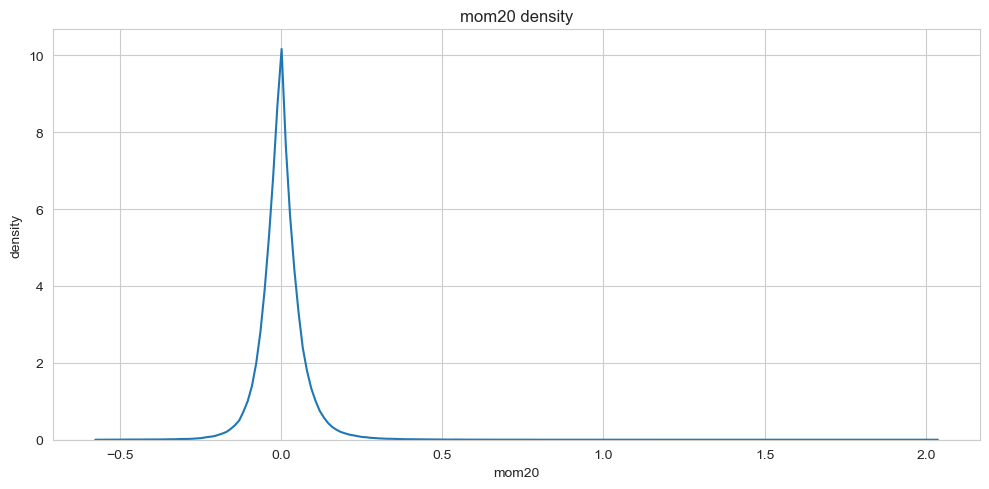

In [6]:
import seaborn as sns

import matplotlib.pyplot as plt

sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))

if hasattr(mom20, 'columns'):          # DataFrame
    for col in mom20.columns:
        sns.kdeplot(mom20[col].dropna(), ax=ax, label=str(col))
    if len(mom20.columns) > 1:
        ax.legend()
else:                                   # Series
    sns.kdeplot(mom20.dropna(), ax=ax)

ax.set_title('mom20 density')
ax.set_xlabel('mom20')
ax.set_ylabel('density')
plt.tight_layout()
plt.show()

In [7]:
momentum.name

'momentum_20'

In [8]:
signal = DiagnosticSignal(name='momentum_20', values=mom20,source_stage='raw',
                          factor_name='momentum_20', recipe={})
rebalance_config = RebalanceConfig(interval=20, anchor=None)
constraint_config = ConstraintConfig()
cost_config = CostConfig(rate=3e-5)
spec = DiagnosticPortfolioSpec(name='momentum_20', harvest_profile=market_rank_ls, 
                               rebalance=rebalance_config, constraint=constraint_config, 
                               cost=cost_config, min_cross_section_size=2,
                               missing_return_policy='default_to_zero_and_warning'
                               )
runner = DiagnosticPortfolioExperimentRunner(signal=signal, dataset=dataset, spec=spec)


In [9]:
eligible = runner._dataset.universe.eligible
main_panel = runner._dataset.main_panel
print(f'universe(eligible) and main_panel has same index: {eligible.index.equals(main_panel.index)}')
print(f'dtype of eligible: {eligible.dtype}')
print(f'missing count in eligible: {eligible.isna().sum()}')
print(f'All signal index in eligible index: {runner._signal.values.index.isin(eligible.index).all()}')

universe(eligible) and main_panel has same index: True
dtype of eligible: bool
missing count in eligible: 0
All signal index in eligible index: True


In [10]:
import pandas as pd
import numpy as np
pd.Series([True, False, False]) & pd.Series([True, True, np.nan])

0     True
1    False
2    False
dtype: bool

In [11]:
result = runner.run()

In [16]:
result.performance

,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods
return_type,,,,,,,
gross,0.726873,0.020513,0.018301,0.068941,0.297545,-0.184840,7591
proxy_net,0.706033,0.020110,0.017891,0.068941,0.291697,-0.188284,7591


<Axes: xlabel='timestamp'>

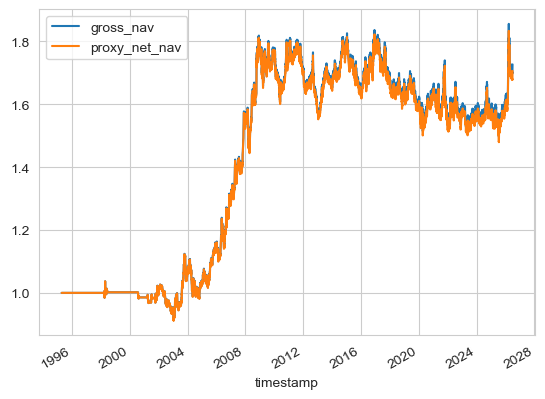

In [15]:
result.nav.plot()